## 1. Kurulum

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import make_scorer, f1_score

os.makedirs("outputs/figures", exist_ok=True)

def grafik_kaydet(ad):
    # O anki grafiği rapor için PNG olarak kaydeder
    plt.savefig(f"outputs/figures/{ad}.png", dpi=150, bbox_inches="tight")

## 2. Temiz verinin yüklenmesi

In [2]:
df = pd.read_csv("data/phishing_temiz.csv")
hedef = df.columns[-1]
X = df.drop(columns=hedef)
y = df[hedef]

print("Boyut:", df.shape)

Boyut: (5772, 31)


## 3. Değerlendirme yöntemi

Bu notebook'taki tüm karşılaştırmalar **train verisi üzerinde 5 katlı stratified cross-validation** ile yapılır. Her katta ayrılan parça validation verisi olarak kullanılır. **Test verisine bu notebook'ta dokunulmaz**, yalnızca en sonda bir kez kullanılacaktır.

Karşılaştırma metriği **phishing sınıfının F1 skorudur**. Hızlı karşılaştırma için Random Forest kullanılır.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_phishing = make_scorer(f1_score, pos_label=-1)   # phishing = -1

def cv_f1(X_, y_, model=None):
    # Verilen veriyle modelin ortalama CV F1 skorunu döndürür (varsayılan: Random Forest)
    if model is None:
        model = RandomForestClassifier(random_state=42, n_jobs=-1)
    return cross_val_score(model, X_, y_, cv=cv, scoring=f1_phishing).mean()

## 4. Train/test ayrımı

Veri **%80 train, %20 test** olarak ayrılır. `stratify` ile iki kümede de sınıf oranları korunur.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True),
              "test": y_test.value_counts(normalize=True)}).round(3)

Train: (4617, 30)  Test: (1155, 30)


,train,test
result,,
-1,0.515,0.515
1,0.485,0.485


## 5. Eksik veriler

Veri setinde eksik değer bulunmamaktadır. Doldurma yöntemlerini karşılaştırmak için train verisinin bir **kopyasında** kontrollü eksiklik oluşturulmuştur:
- Hedefle en ilişkili 5 özellikte, her birinde rastgele **%8** hücre silinir (tamamen rastgele eksiklik, MCAR).
- Silinen hücrelerin gerçek değerleri bilindiği için her yöntemin **doldurma doğruluğu** ölçülebilir.
- Yöntemler ayrıca doldurulmuş veriyle elde edilen **CV F1** skoruyla karşılaştırılır.

Bu bir deneydir. Modellerin eğitiminde gerçek, eksiksiz veri kullanılmaya devam eder.

### 5.1 Yapay eksik veri oluşturma

In [6]:
eksik_sutunlar = ["sslfinal_state", "url_of_anchor", "web_traffic", "prefix_suffix", "having_sub_domain"]
oran = 0.08
rng = np.random.default_rng(42)

X_train_eksik = X_train.copy()      # asıl X_train değişmez
for col in eksik_sutunlar:
    idx = rng.choice(X_train_eksik.index, size=int(len(X_train_eksik) * oran), replace=False)
    X_train_eksik.loc[idx, col] = np.nan

print(X_train_eksik[eksik_sutunlar].isnull().sum())
print("\nSatır silinseydi kalan:", len(X_train_eksik.dropna()), "/", len(X_train_eksik))

sslfinal_state       369
url_of_anchor        369
web_traffic          369
prefix_suffix        369
having_sub_domain    369
dtype: int64

Satır silinseydi kalan: 3027 / 4617


### 5.2 Doldurma yöntemlerinin karşılaştırılması

- **Referans:** eksiksiz veri (ulaşılabilecek en iyi durum)
- **Satır silme:** eksik değer içeren satırların atılması
- **Mod:** en sık görülen değerle doldurma
- **Medyan:** ortanca değerle doldurma
- **KNN:** en yakın 5 komşunun değerlerine göre doldurma

Özellikler kategorik (-1/0/1) olduğu için ortalama ile doldurma kullanılmamıştır, 0,37 gibi anlamsız değerler üretir. KNN de ortalama aldığı için sonucu sütunun aldığı en yakın değere yuvarlanır.

In [7]:
def gecerli_degere_yuvarla(X_dolu):
    # KNN'in ürettiği ondalıklı değeri (ör. 0.4) sütunun aldığı en yakın değere (-1/0/1) yuvarlar
    for col in eksik_sutunlar:
        izinli = np.sort(X_train[col].unique())
        X_dolu[col] = X_dolu[col].apply(lambda v: izinli[np.abs(izinli - v).argmin()])
    return X_dolu

yontemler = {
    "Mod (en sık değer)": SimpleImputer(strategy="most_frequent"),
    "Medyan": SimpleImputer(strategy="median"),
    "KNN (k=5)": KNNImputer(n_neighbors=5),
}

maske = X_train_eksik[eksik_sutunlar].isna()    # silinen hücrelerin yerleri
satir = X_train_eksik.dropna().index             # hiç eksiği olmayan satırlar

sonuclar = [
    {"yontem": "Referans (eksiksiz veri)", "doldurma_dogrulugu": np.nan, "cv_f1": cv_f1(X_train, y_train)},
    {"yontem": "Satır silme", "doldurma_dogrulugu": np.nan, "cv_f1": cv_f1(X_train.loc[satir], y_train.loc[satir])},
]
for ad, imp in yontemler.items():
    X_dolu = pd.DataFrame(imp.fit_transform(X_train_eksik), columns=X_train.columns, index=X_train.index)
    if ad.startswith("KNN"):
        X_dolu = gecerli_degere_yuvarla(X_dolu)

    # Doldurma doğruluğu: silinen hücrelerin yüzde kaçı gerçek değeriyle dolduruldu
    dogru = (X_dolu[eksik_sutunlar][maske] == X_train[eksik_sutunlar][maske]).sum().sum()
    sonuclar.append({"yontem": ad,
                     "doldurma_dogrulugu": dogru / maske.sum().sum(),
                     "cv_f1": cv_f1(X_dolu, y_train)})

eksik_sonuc = pd.DataFrame(sonuclar).round(4)
eksik_sonuc.to_csv("outputs/eksik_veri_deneyi.csv", index=False)
eksik_sonuc

,yontem,doldurma_dogrulugu,cv_f1
0,Referans (eksiksiz veri),NaN,0.9573
1,Satır silme,NaN,0.9551
2,Mod (en sık değer),0.5366,0.9456
3,Medyan,0.4943,0.9449
4,KNN (k=5),0.5799,0.9452


## 6. Feature engineering

Her site için iki yeni özellik türetilir:
- `phishing_isaret_sayisi`: değeri -1 (phishing belirtisi) olan özellik sayısı
- `supheli_isaret_sayisi`: değeri 0 (şüpheli) olan özellik sayısı

Bu özellikler satır bazında hesaplandığı ve veriden bir istatistik öğrenmediği için test verisine de aynen uygulanır. Katkıları hem ağaç tabanlı hem doğrusal bir model üzerinde ölçülür.

In [8]:
def ozellik_turet(X_):
    yeni = X_.copy()
    yeni["phishing_isaret_sayisi"] = (X_ == -1).sum(axis=1)
    yeni["supheli_isaret_sayisi"] = (X_ == 0).sum(axis=1)
    return yeni

X_train_fe = ozellik_turet(X_train)
X_test_fe = ozellik_turet(X_test)

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
fe_sonuc = pd.DataFrame({
    "model": ["Random Forest", "Logistic Regression"],
    "orijinal_ozellikler": [cv_f1(X_train, y_train), cv_f1(X_train, y_train, lr)],
    "turetilmis_ozelliklerle": [cv_f1(X_train_fe, y_train), cv_f1(X_train_fe, y_train, lr)],
}).round(4)
fe_sonuc.to_csv("outputs/feature_engineering.csv", index=False)
fe_sonuc

,model,orijinal_ozellikler,turetilmis_ozelliklerle
0,Random Forest,0.9573,0.9580
1,Logistic Regression,0.9276,0.9274


## 7. Feature selection

### 7.1 Feature importance

İki farklı yöntemle özelliklerin önemi ölçülür:
- **Mutual information:** modelden bağımsız, özelliğin hedef hakkında ne kadar bilgi taşıdığı
- **Random Forest önem skoru:** modelin kararlarında özelliğin ne kadar kullanıldığı

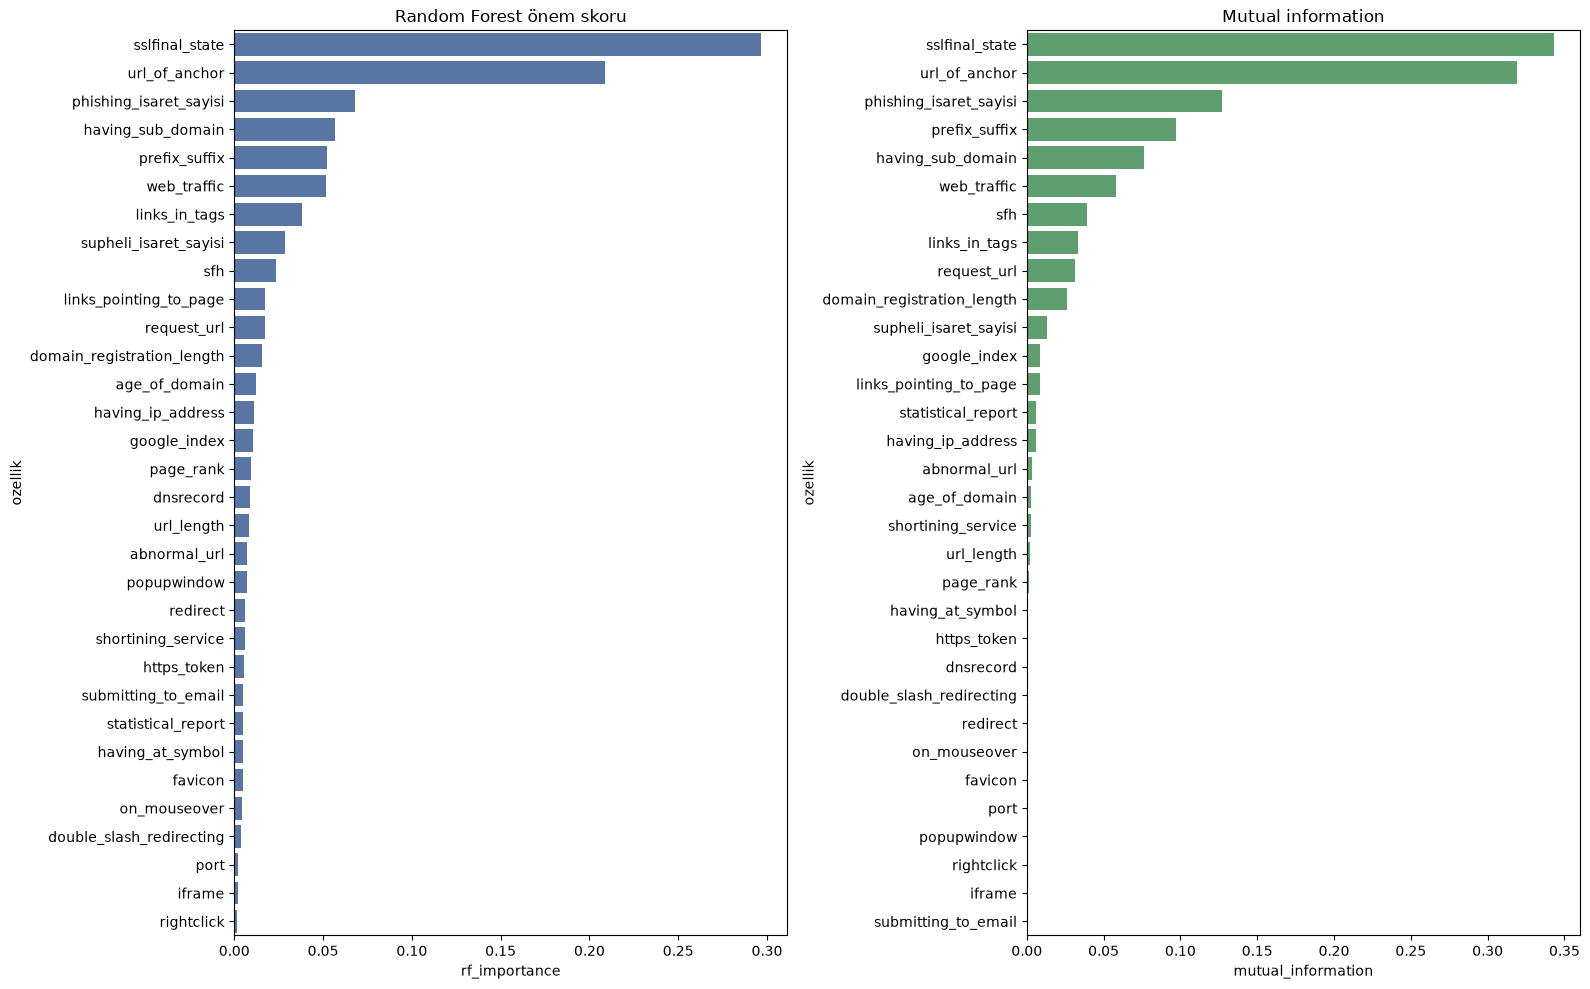

In [9]:
mi = mutual_info_classif(X_train_fe, y_train, discrete_features=True, random_state=42)
rf = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_train_fe, y_train)

onem = pd.DataFrame({
    "ozellik": X_train_fe.columns,
    "mutual_information": mi,
    "rf_importance": rf.feature_importances_,
}).sort_values("rf_importance", ascending=False).reset_index(drop=True)
onem.to_csv("outputs/feature_importance.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
sns.barplot(data=onem, y="ozellik", x="rf_importance", ax=axes[0], color="#4c72b0")
axes[0].set_title("Random Forest önem skoru")
sns.barplot(data=onem.sort_values("mutual_information", ascending=False),
            y="ozellik", x="mutual_information", ax=axes[1], color="#55a868")
axes[1].set_title("Mutual information")
plt.tight_layout()
grafik_kaydet("feature_importance")
plt.show()

### 7.2 Birbirine çok bağlı özellikler

Korelasyonu |r| > 0,9 olan özellik çiftleri büyük ölçüde aynı bilgiyi taşır. Her çiftten mutual information değeri düşük olan çıkarılır.

In [10]:
kor = X_train_fe.corr().abs()
ust = kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1))   # her çift bir kez
ciftler = ust.stack()[lambda s: s > 0.9]
print(ciftler)

mi_skor = onem.set_index("ozellik")["mutual_information"]
cikarilacak = {a if mi_skor[a] < mi_skor[b] else b for a, b in ciftler.index}
print("\nÇıkarılacak:", cikarilacak)

favicon  popupwindow    0.934143
dtype: float64

Çıkarılacak: {'popupwindow'}


### 7.3 Özellik sayısına göre performans

Kalan özellikler Random Forest önem sırasına göre eklenir ve her adımda CV F1 ölçülür.

   ozellik_sayisi   cv_f1
0               5  0.9183
1              10  0.9418
2              15  0.9538
3              20  0.9555
4              25  0.9572
5              31  0.9584


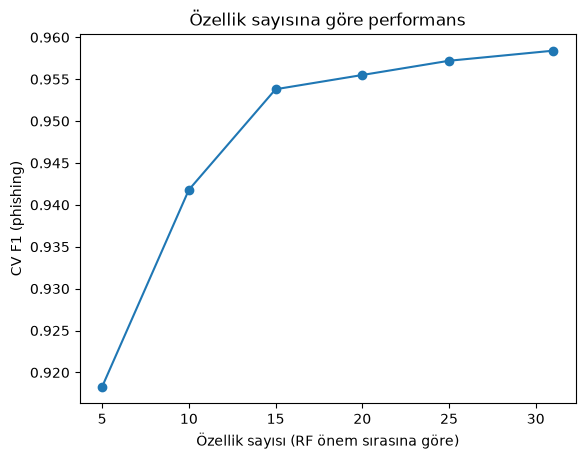

In [11]:
sirali = [o for o in onem["ozellik"] if o not in cikarilacak]
k_degerleri = [5, 10, 15, 20, 25, len(sirali)]

secim = pd.DataFrame({
    "ozellik_sayisi": k_degerleri,
    "cv_f1": [cv_f1(X_train_fe[sirali[:k]], y_train) for k in k_degerleri],
}).round(4)
secim.to_csv("outputs/ozellik_secimi.csv", index=False)
print(secim)

plt.plot(secim["ozellik_sayisi"], secim["cv_f1"], marker="o")
plt.xlabel("Özellik sayısı (RF önem sırasına göre)")
plt.ylabel("CV F1 (phishing)")
plt.title("Özellik sayısına göre performans")
grafik_kaydet("ozellik_sayisi_performans")
plt.show()

### 7.4 Seçim

En yüksek CV F1 skorunu veren özellik sayısı seçilir. Skorlar birbirine çok yakınsa daha az özellik tercih edilebilir, bu durumda `en_iyi_k` elle verilebilir.

In [12]:
en_iyi_k = secim.loc[secim["cv_f1"].idxmax(), "ozellik_sayisi"]
secilen_ozellikler = sirali[:en_iyi_k]

print(f"Seçilen özellik sayısı: {en_iyi_k}")
print(secilen_ozellikler)

Seçilen özellik sayısı: 31
['sslfinal_state', 'url_of_anchor', 'phishing_isaret_sayisi', 'having_sub_domain', 'prefix_suffix', 'web_traffic', 'links_in_tags', 'supheli_isaret_sayisi', 'sfh', 'links_pointing_to_page', 'request_url', 'domain_registration_length', 'age_of_domain', 'having_ip_address', 'google_index', 'page_rank', 'dnsrecord', 'url_length', 'abnormal_url', 'redirect', 'shortining_service', 'https_token', 'submitting_to_email', 'statistical_report', 'having_at_symbol', 'favicon', 'on_mouseover', 'double_slash_redirecting', 'port', 'iframe', 'rightclick']


## 8. Standardizasyon

Orijinal özellikler -1/0/1 aralığındadır, türetilen sayım özellikleri ise 0–30 aralığındadır. Bu ölçek farkı mesafe ve katsayı tabanlı modelleri (**Logistic Regression, KNN, SVM**) etkiler, bu yüzden bu modellerde **StandardScaler** (ortalama 0, standart sapma 1) kullanılır. Ağaç tabanlı modeller (Random Forest, XGBoost) ölçekten etkilenmez.

Asıl uygulama 04 ve 05 notebook'larında **pipeline içinde** yapılacaktır. Böylece ölçekleyici her CV katında sadece o katın train kısmına fit edilir. Aşağıda yalnızca etkisi gösterilmektedir.

In [13]:
olcekleyici = StandardScaler().fit(X_train_fe[secilen_ozellikler])   # sadece train'e fit
olcekli = pd.DataFrame(olcekleyici.transform(X_train_fe[secilen_ozellikler]), columns=secilen_ozellikler)

pd.DataFrame({
    "önce_ort": X_train_fe[secilen_ozellikler].mean(),
    "önce_std": X_train_fe[secilen_ozellikler].std(),
    "sonra_ort": olcekli.mean().values,
    "sonra_std": olcekli.std().values,
}).round(2)

,önce_ort,önce_std,sonra_ort,sonra_std
sslfinal_state,0.16,0.92,0.0,1.0
url_of_anchor,-0.14,0.73,-0.0,1.0
phishing_isaret_sayisi,9.38,3.69,0.0,1.0
having_sub_domain,0.07,0.81,-0.0,1.0
prefix_suffix,-0.76,0.65,0.0,1.0
web_traffic,0.22,0.83,0.0,1.0
links_in_tags,-0.14,0.77,-0.0,1.0
supheli_isaret_sayisi,3.07,1.27,0.0,1.0
sfh,-0.58,0.76,-0.0,1.0
links_pointing_to_page,0.35,0.58,0.0,1.0


## 9. Kaydetme

Seçilen özelliklerle train ve test verileri **ölçeklenmemiş** halde kaydedilir. Sonraki notebook'lar bu dosyalardan okur.

In [14]:
X_train_fe[secilen_ozellikler].to_csv("outputs/X_train.csv", index=False)
X_test_fe[secilen_ozellikler].to_csv("outputs/X_test.csv", index=False)
y_train.to_csv("outputs/y_train.csv", index=False)
y_test.to_csv("outputs/y_test.csv", index=False)

print("Kaydedildi: outputs/X_train.csv, X_test.csv, y_train.csv, y_test.csv")

Kaydedildi: outputs/X_train.csv, X_test.csv, y_train.csv, y_test.csv
